# 03 — CNN vs ConvLSTM Comparison (Channel 1)

This notebook compares the saved CNN and ConvLSTM results for six-hour-ahead wind-speed forecasting.

**What it does**
1. Loads both models' metrics and test-prediction CSV files from Google Drive.
2. Inspects the CSV columns and identifies common sample identifiers (preferably cyclone ID + timestamp).
3. Matches the predictions for the same test observations.
4. Recalculates MAE and RMSE on the matched observations only.
5. Displays comparison tables and charts.

> Important: the reported headline metrics from the two training notebooks are not enough to prove that their test rows are identical. This notebook checks the prediction files first. It will stop with a clear message if it cannot safely identify matching observations rather than silently comparing unrelated rows.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_DIR = Path('/content/drive/MyDrive/cyclone/model_results')

cnn_metrics_path = RESULTS_DIR / 'cnn_channel1_metrics.json'
cnn_predictions_path = RESULTS_DIR / 'cnn_channel1_test_predictions.csv'
convlstm_metrics_path = RESULTS_DIR / 'convlstm_channel1_metrics.json'
convlstm_predictions_path = RESULTS_DIR / 'convlstm_channel1_test_predictions.csv'

for path in [cnn_metrics_path, cnn_predictions_path, convlstm_metrics_path, convlstm_predictions_path]:
    print(('FOUND  ' if path.exists() else 'MISSING'), path)

if not all(p.exists() for p in [cnn_metrics_path, cnn_predictions_path, convlstm_metrics_path, convlstm_predictions_path]):
    raise FileNotFoundError(
        'One or more files are missing. Check that both model notebooks saved their metrics and prediction CSVs '
        'under My Drive/cyclone/model_results/.'
    )

with open(cnn_metrics_path, 'r') as f:
    cnn_metrics = json.load(f)
with open(convlstm_metrics_path, 'r') as f:
    convlstm_metrics = json.load(f)

cnn_df = pd.read_csv(cnn_predictions_path)
convlstm_df = pd.read_csv(convlstm_predictions_path)

print('CNN metrics:', cnn_metrics)
print('ConvLSTM metrics:', convlstm_metrics)
print('\nCNN prediction columns:', cnn_df.columns.tolist())
print('ConvLSTM prediction columns:', convlstm_df.columns.tolist())

display(cnn_df.head())
display(convlstm_df.head())

FOUND   /content/drive/MyDrive/cyclone/model_results/cnn_channel1_metrics.json
FOUND   /content/drive/MyDrive/cyclone/model_results/cnn_channel1_test_predictions.csv
FOUND   /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_metrics.json
FOUND   /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_test_predictions.csv
CNN metrics: {'model': 'CNN', 'channel': 1, 'input': 'single 64x64 satellite image', 'target': 'TARGET_WIND (six-hour-ahead wind speed, knots)', 'test_samples': 1013, 'test_mae_knots': 12.823071479797363, 'test_rmse_knots': 17.667119338276137, 'normalization_train_pixel_mean': 239.26144846078967, 'normalization_train_pixel_std': 31.93635833397661}
ConvLSTM metrics: {'model': 'ConvLSTM', 'channel': 1, 'input': 'four 64x64 satellite images, 3 hours apart', 'target': 'TARGET_WIND (six-hour-ahead wind speed, knots)', 'test_samples': 1013, 'test_mae_knots': 12.525308609008789, 'test_rmse_knots': 17.015583749376077, 'normalization_train_pixel_mean': 238.52

,SID,T,actual_wind_knots,predicted_wind_knots
0,2024145N14087,2024-05-24 18:00:00,30.0,20.333147
1,2024145N14087,2024-05-24 21:00:00,30.0,22.763040
2,2024145N14087,2024-05-25 09:00:00,35.0,37.242000
3,2024141N03142,2024-05-25 12:00:00,45.0,44.339237
4,2024145N14087,2024-05-25 12:00:00,40.0,28.479460


,SID,END_TIME,actual_wind_knots,predicted_wind_knots
0,2024141N03142,2024-05-25 06:00:00,35.0,53.135834
1,2024141N03142,2024-05-25 12:00:00,45.0,59.963710
2,2024141N03142,2024-05-25 18:00:00,50.0,43.782604
3,2024141N03142,2024-05-26 00:00:00,55.0,46.100414
4,2024141N03142,2024-05-26 06:00:00,65.0,62.963203


## Match the same test observations

The code below looks for a cyclone identifier (such as `SID`) and a timestamp (such as `ISO_TIME` or `timestamp`). It can also use a unique sample/patch identifier if one is present in **both** files.

It deliberately does **not** match rows just by their row number: the two CSVs could be ordered differently.

In [7]:
def normalize_colname(name):
    return ''.join(ch.lower() for ch in str(name) if ch.isalnum())

def find_column(df, aliases):
    lookup = {normalize_colname(c): c for c in df.columns}
    for alias in aliases:
        key = normalize_colname(alias)
        if key in lookup:
            return lookup[key]
    return None

# Common identifier aliases. Use only fields that exist in both prediction files.
sid_aliases = ['SID', 'storm_id', 'cyclone_id', 'stormid']
time_aliases = ['T', 'END_TIME', 'ISO_TIME', 'timestamp', 'datetime', 'time', 'valid_time', 'target_time']
sample_aliases = ['sample_id', 'sequence_id', 'patch_id', 'observation_id', 'row_id', 'index']

cnn_sid = find_column(cnn_df, sid_aliases)
conv_sid = find_column(convlstm_df, sid_aliases)
cnn_time = find_column(cnn_df, time_aliases)
conv_time = find_column(convlstm_df, time_aliases)

join_keys = []
key_pairs = []

if cnn_sid and conv_sid and cnn_time and conv_time:
    join_keys = ['_match_sid', '_match_time']
    cnn_df['_match_sid'] = cnn_df[cnn_sid].astype(str).str.strip()
    convlstm_df['_match_sid'] = convlstm_df[conv_sid].astype(str).str.strip()
    cnn_df['_match_time'] = pd.to_datetime(cnn_df[cnn_time], errors='coerce').astype('string')
    convlstm_df['_match_time'] = pd.to_datetime(convlstm_df[conv_time], errors='coerce').astype('string')
    key_pairs = [(cnn_sid, conv_sid), (cnn_time, conv_time)]
    print(f'Matching on cyclone ID ({cnn_sid}, {conv_sid}) + timestamp ({cnn_time}, {conv_time}).')
else:
    # Fall back only to an identifier that exists in both files.
    cnn_sample = find_column(cnn_df, sample_aliases)
    conv_sample = find_column(convlstm_df, sample_aliases)
    if cnn_sample and conv_sample:
        join_keys = ['_match_sample']
        cnn_df['_match_sample'] = cnn_df[cnn_sample].astype(str).str.strip()
        convlstm_df['_match_sample'] = convlstm_df[conv_sample].astype(str).str.strip()
        key_pairs = [(cnn_sample, conv_sample)]
        print(f'Matching on shared sample identifier ({cnn_sample}, {conv_sample}).')

if not join_keys:
    print('Unable to safely identify common test observations.')
    print('Available CNN columns:', cnn_df.columns.tolist())
    print('Available ConvLSTM columns:', convlstm_df.columns.tolist())
    raise ValueError(
        'The prediction CSVs need shared identifiers (preferably SID + timestamp, or a stable sample ID). '
        'Do not compare by row number. Add these identifiers when exporting predictions from the model notebooks, '
        'then rerun this comparison notebook.'
    )

# Identify actual and predicted-value columns in each file.
actual_aliases = [
    'actual_wind_knots',
    'actual_wind',
    'y_true',
    'ytrue',
    'actual',
    'target_wind',
    'TARGET_WIND',
    'true_wind',
    'actual_knots'
]

pred_aliases = [
    'predicted_wind_knots',
    'predicted_wind',
    'y_pred',
    'ypred',
    'prediction',
    'predicted',
    'pred_wind',
    'prediction_knots'
]

cnn_actual = find_column(cnn_df, actual_aliases)
conv_actual = find_column(convlstm_df, actual_aliases)
cnn_pred = find_column(cnn_df, pred_aliases)
conv_pred = find_column(convlstm_df, pred_aliases)

print('Detected columns:')
print('CNN actual:', cnn_actual, '| CNN prediction:', cnn_pred)
print('ConvLSTM actual:', conv_actual, '| ConvLSTM prediction:', conv_pred)

if not all([cnn_actual, conv_actual, cnn_pred, conv_pred]):
    raise ValueError(
        'Could not automatically detect actual/predicted wind columns. Check the displayed CSV columns and update '
        'actual_aliases/pred_aliases in this cell to match your files.'
    )

# Rename measurement columns to common names before joining.
cnn_join = cnn_df[join_keys + [cnn_actual, cnn_pred]].copy()
cnn_join = cnn_join.rename(columns={cnn_actual: 'actual_cnn', cnn_pred: 'prediction_cnn'})
conv_join = convlstm_df[join_keys + [conv_actual, conv_pred]].copy()
conv_join = conv_join.rename(columns={conv_actual: 'actual_convlstm', conv_pred: 'prediction_convlstm'})

# Avoid ambiguous many-to-many joins. Duplicate keys need to be investigated, not silently multiplied.
if cnn_join.duplicated(join_keys).any():
    raise ValueError('CNN prediction file has duplicate matching keys. Check the identifier columns before comparing.')
if conv_join.duplicated(join_keys).any():
    raise ValueError('ConvLSTM prediction file has duplicate matching keys. Check the identifier columns before comparing.')

matched = pd.merge(cnn_join, conv_join, on=join_keys, how='inner')
print(f'CNN rows: {len(cnn_join):,}')
print(f'ConvLSTM rows: {len(conv_join):,}')
print(f'Matched observations: {len(matched):,}')

if matched.empty:
    raise ValueError('No matching observations found. Check that the key columns represent the same target time in both files.')

# Keep only observations where both actual targets and both predictions are finite.
numeric_cols = ['actual_cnn', 'prediction_cnn', 'actual_convlstm', 'prediction_convlstm']
for col in numeric_cols:
    matched[col] = pd.to_numeric(matched[col], errors='coerce')
matched = matched.replace([np.inf, -np.inf], np.nan).dropna(subset=numeric_cols).copy()

# The actual target should agree across models for the same observation.
matched['actual_target_difference'] = (matched['actual_cnn'] - matched['actual_convlstm']).abs()
target_mismatches = int((matched['actual_target_difference'] > 1e-5).sum())
print(f'Rows with differing actual targets between files: {target_mismatches}')

if target_mismatches:
    print('WARNING: some matched keys have different actual wind targets. These rows will be excluded from the fair comparison.')
    matched = matched[matched['actual_target_difference'] <= 1e-5].copy()

if matched.empty:
    raise ValueError('No matched observations remain after checking actual target consistency.')

matched['actual_wind'] = (matched['actual_cnn'] + matched['actual_convlstm']) / 2
print(f'Final common observations used for comparison: {len(matched):,}')
display(matched.head())

Matching on cyclone ID (SID, SID) + timestamp (T, END_TIME).
Detected columns:
CNN actual: actual_wind_knots | CNN prediction: predicted_wind_knots
ConvLSTM actual: actual_wind_knots | ConvLSTM prediction: predicted_wind_knots
CNN rows: 1,013
ConvLSTM rows: 1,013
Matched observations: 1,013
Rows with differing actual targets between files: 0
Final common observations used for comparison: 1,013


,_match_sid,_match_time,actual_cnn,prediction_cnn,actual_convlstm,prediction_convlstm,actual_target_difference,actual_wind
0,2024145N14087,2024-05-24 18:00:00,30.0,20.333147,30.0,35.587450,0.0,30.0
1,2024145N14087,2024-05-24 21:00:00,30.0,22.763040,30.0,26.279190,0.0,30.0
2,2024145N14087,2024-05-25 09:00:00,35.0,37.242000,35.0,31.340900,0.0,35.0
3,2024141N03142,2024-05-25 12:00:00,45.0,44.339237,45.0,59.963710,0.0,45.0
4,2024145N14087,2024-05-25 12:00:00,40.0,28.479460,40.0,27.389986,0.0,40.0


## Calculate metrics on the common test observations

Both models are evaluated on exactly the same matched rows below. Lower MAE and RMSE indicate smaller prediction errors.

In [8]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = predicted - actual
    return {
        'MAE (knots)': float(np.mean(np.abs(errors))),
        'RMSE (knots)': float(np.sqrt(np.mean(errors ** 2))),
    }

cnn_common = regression_metrics(matched['actual_wind'], matched['prediction_cnn'])
convlstm_common = regression_metrics(matched['actual_wind'], matched['prediction_convlstm'])

comparison = pd.DataFrame([
    {'Model': 'CNN', 'Input': 'One Channel 1 image', 'Common test samples': len(matched), **cnn_common},
    {'Model': 'ConvLSTM', 'Input': 'Four Channel 1 images, 3 hours apart', 'Common test samples': len(matched), **convlstm_common},
])

display(comparison.round(4))

cnn_mae = cnn_common['MAE (knots)']
conv_mae = convlstm_common['MAE (knots)']
cnn_rmse = cnn_common['RMSE (knots)']
conv_rmse = convlstm_common['RMSE (knots)']

mae_improvement = ((cnn_mae - conv_mae) / cnn_mae * 100) if cnn_mae else np.nan
rmse_improvement = ((cnn_rmse - conv_rmse) / cnn_rmse * 100) if cnn_rmse else np.nan

print(f'MAE change in favor of ConvLSTM: {mae_improvement:.2f}% (positive means ConvLSTM is better)')
print(f'RMSE change in favor of ConvLSTM: {rmse_improvement:.2f}% (positive means ConvLSTM is better)')

if conv_mae < cnn_mae and conv_rmse < cnn_rmse:
    print('Conclusion on matched rows: ConvLSTM has lower MAE and RMSE.')
elif cnn_mae < conv_mae and cnn_rmse < conv_rmse:
    print('Conclusion on matched rows: CNN has lower MAE and RMSE.')
else:
    print('Conclusion on matched rows: the metrics disagree; one model is not better on both metrics.')

,Model,Input,Common test samples,MAE (knots),RMSE (knots)
0,CNN,One Channel 1 image,1013,12.8231,17.6671
1,ConvLSTM,"Four Channel 1 images, 3 hours apart",1013,12.5253,17.0156


MAE change in favor of ConvLSTM: 2.32% (positive means ConvLSTM is better)
RMSE change in favor of ConvLSTM: 3.69% (positive means ConvLSTM is better)
Conclusion on matched rows: ConvLSTM has lower MAE and RMSE.


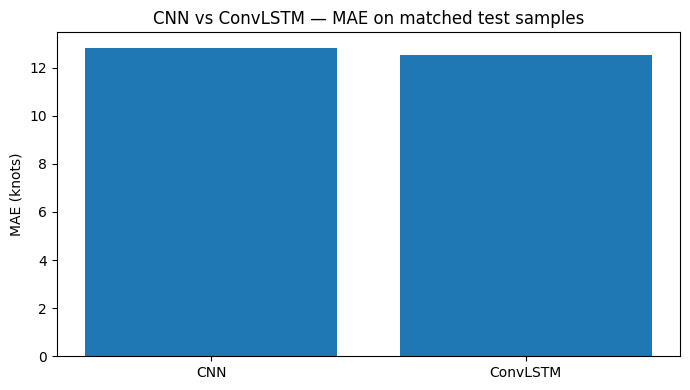

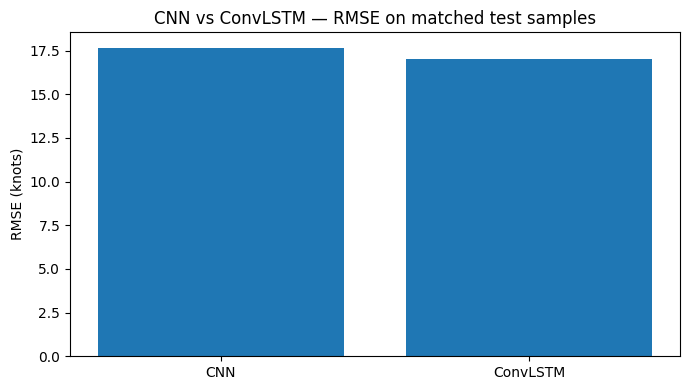

In [9]:
# Bar charts for the common-sample comparison
plt.figure(figsize=(7, 4))
plt.bar(comparison['Model'], comparison['MAE (knots)'])
plt.ylabel('MAE (knots)')
plt.title('CNN vs ConvLSTM — MAE on matched test samples')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(comparison['Model'], comparison['RMSE (knots)'])
plt.ylabel('RMSE (knots)')
plt.title('CNN vs ConvLSTM — RMSE on matched test samples')
plt.tight_layout()
plt.show()

## Optional: compare prediction errors

This plot shows the distribution of absolute errors for the same matched observations. It can help reveal whether one model tends to make larger mistakes.

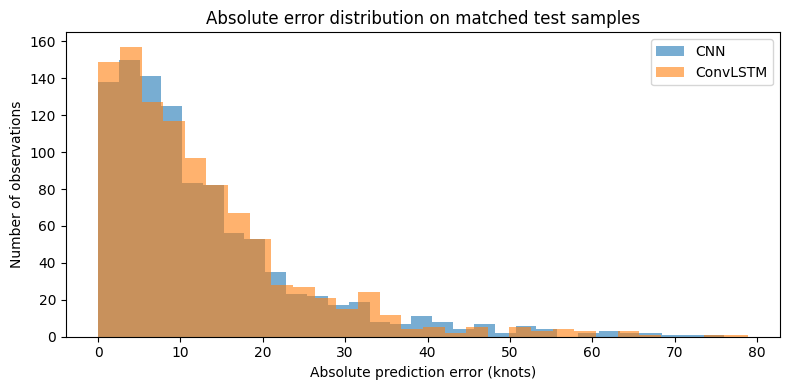

In [10]:
matched['cnn_absolute_error'] = (matched['prediction_cnn'] - matched['actual_wind']).abs()
matched['convlstm_absolute_error'] = (matched['prediction_convlstm'] - matched['actual_wind']).abs()

plt.figure(figsize=(8, 4))
plt.hist(matched['cnn_absolute_error'], bins=30, alpha=0.6, label='CNN')
plt.hist(matched['convlstm_absolute_error'], bins=30, alpha=0.6, label='ConvLSTM')
plt.xlabel('Absolute prediction error (knots)')
plt.ylabel('Number of observations')
plt.title('Absolute error distribution on matched test samples')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Save the fair comparison table and matched predictions to Google Drive
comparison_path = RESULTS_DIR / 'channel1_model_comparison_common_samples.csv'
matched_path = RESULTS_DIR / 'channel1_matched_test_predictions.csv'

comparison.to_csv(comparison_path, index=False)
matched.to_csv(matched_path, index=False)

print('Saved comparison table:', comparison_path)
print('Saved matched predictions:', matched_path)

Saved comparison table: /content/drive/MyDrive/cyclone/model_results/channel1_model_comparison_common_samples.csv
Saved matched predictions: /content/drive/MyDrive/cyclone/model_results/channel1_matched_test_predictions.csv
